In [ ]:
%pip -q install pyspark

In [ ]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Tarea3_BigData") \
    .master("local[*]") \
    .getOrCreate()

print("¡Spark se inició correctamente!")
print("Versión de Spark:", spark.version)


¡Spark se inició correctamente!
Versión de Spark: 4.0.4


In [1]:

from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Tarea3_BigData") \
    .master("local[*]") \
    .getOrCreate()

datos = [
    (1, "Cuaderno", "Papeleria", 3, 2500),
    (2, "Lapiz", "Papeleria", 10, 800),
    (3, "Mouse", "Tecnologia", 2, 25000),
    (4, "Teclado", "Tecnologia", 1, 45000),
    (5, "Cuaderno", "Papeleria", 4, 2500),
    (6, "Audifonos", "Tecnologia", 2, 30000),
    (7, "Lapiz", "Papeleria", 5, 800),
    (8, "Mouse", "Tecnologia", 1, 25000)
]

columnas = [
    "id_venta", "producto", "categoria",
    "cantidad", "precio_unitario"
]

df = spark.createDataFrame(datos, columnas)

print("Datos originales:")
df.show()

print("Estructura de los datos:")
df.printSchema()


Datos originales:
+--------+---------+----------+--------+---------------+
|id_venta| producto| categoria|cantidad|precio_unitario|
+--------+---------+----------+--------+---------------+
|       1| Cuaderno| Papeleria|       3|           2500|
|       2|    Lapiz| Papeleria|      10|            800|
|       3|    Mouse|Tecnologia|       2|          25000|
|       4|  Teclado|Tecnologia|       1|          45000|
|       5| Cuaderno| Papeleria|       4|           2500|
|       6|Audifonos|Tecnologia|       2|          30000|
|       7|    Lapiz| Papeleria|       5|            800|
|       8|    Mouse|Tecnologia|       1|          25000|
+--------+---------+----------+--------+---------------+

Estructura de los datos:
root
 |-- id_venta: long (nullable = true)
 |-- producto: string (nullable = true)
 |-- categoria: string (nullable = true)
 |-- cantidad: long (nullable = true)
 |-- precio_unitario: long (nullable = true)



In [2]:

from pyspark.sql.functions import col, sum as sum_, count

print("Registros originales:", df.count())
print("Registros duplicados:", df.count() - df.dropDuplicates().count())

print("Valores vacíos por columna:")
df.select([
    sum_(col(c).isNull().cast("int")).alias(c)
    for c in df.columns
]).show()

df_limpio = df.dropDuplicates().dropna()

print("Registros después de la limpieza:", df_limpio.count())
df_limpio.show()


Registros originales: 8
Registros duplicados: 0
Valores vacíos por columna:
+--------+--------+---------+--------+---------------+
|id_venta|producto|categoria|cantidad|precio_unitario|
+--------+--------+---------+--------+---------------+
|       0|       0|        0|       0|              0|
+--------+--------+---------+--------+---------------+

Registros después de la limpieza: 8
+--------+---------+----------+--------+---------------+
|id_venta| producto| categoria|cantidad|precio_unitario|
+--------+---------+----------+--------+---------------+
|       1| Cuaderno| Papeleria|       3|           2500|
|       3|    Mouse|Tecnologia|       2|          25000|
|       2|    Lapiz| Papeleria|      10|            800|
|       4|  Teclado|Tecnologia|       1|          45000|
|       5| Cuaderno| Papeleria|       4|           2500|
|       6|Audifonos|Tecnologia|       2|          30000|
|       7|    Lapiz| Papeleria|       5|            800|
|       8|    Mouse|Tecnologia|       1|  

In [3]:

from pyspark.sql.functions import col

df_ventas = df_limpio.withColumn(
    "ingreso",
    col("cantidad") * col("precio_unitario")
)

print("Ventas con el ingreso calculado:")
df_ventas.show()


Ventas con el ingreso calculado:
+--------+---------+----------+--------+---------------+-------+
|id_venta| producto| categoria|cantidad|precio_unitario|ingreso|
+--------+---------+----------+--------+---------------+-------+
|       1| Cuaderno| Papeleria|       3|           2500|   7500|
|       3|    Mouse|Tecnologia|       2|          25000|  50000|
|       2|    Lapiz| Papeleria|      10|            800|   8000|
|       4|  Teclado|Tecnologia|       1|          45000|  45000|
|       5| Cuaderno| Papeleria|       4|           2500|  10000|
|       6|Audifonos|Tecnologia|       2|          30000|  60000|
|       7|    Lapiz| Papeleria|       5|            800|   4000|
|       8|    Mouse|Tecnologia|       1|          25000|  25000|
+--------+---------+----------+--------+---------------+-------+



In [4]:

from pyspark.sql.functions import sum as sum_

por_producto = (
    df_ventas
    .groupBy("producto")
    .agg(sum_("ingreso").alias("ingreso_total"))
    .orderBy(col("ingreso_total").desc())
)

print("Ingresos totales por producto:")
por_producto.show()


Ingresos totales por producto:
+---------+-------------+
| producto|ingreso_total|
+---------+-------------+
|    Mouse|        75000|
|Audifonos|        60000|
|  Teclado|        45000|
| Cuaderno|        17500|
|    Lapiz|        12000|
+---------+-------------+



In [5]:

from pyspark.sql.functions import count, sum as sum_

por_categoria = (
    df_ventas
    .groupBy("categoria")
    .agg(
        count("*").alias("numero_lineas"),
        sum_("ingreso").alias("ingreso_total")
    )
    .orderBy(col("ingreso_total").desc())
)

print("Resultados por categoría:")
por_categoria.show()


Resultados por categoría:
+----------+-------------+-------------+
| categoria|numero_lineas|ingreso_total|
+----------+-------------+-------------+
|Tecnologia|            4|       180000|
| Papeleria|            4|        29500|
+----------+-------------+-------------+



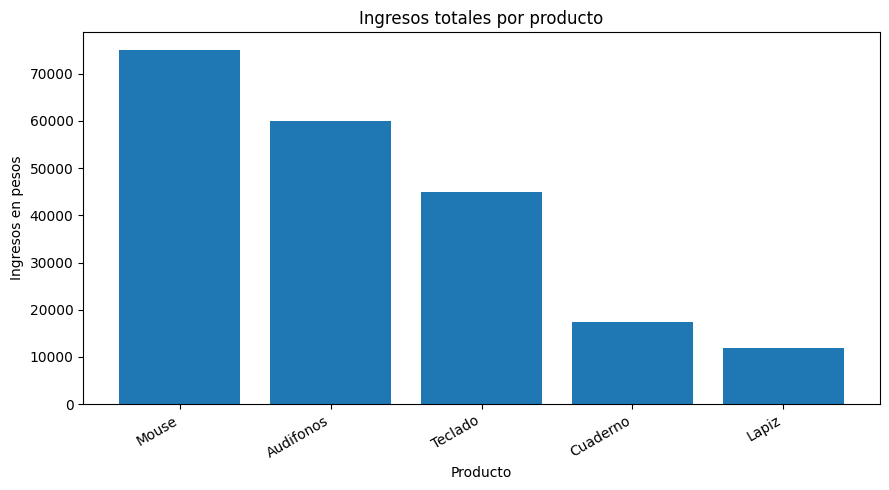

In [6]:

import matplotlib.pyplot as plt

datos_grafica = por_producto.toPandas()

plt.figure(figsize=(9, 5))
plt.bar(
    datos_grafica["producto"],
    datos_grafica["ingreso_total"]
)

plt.title("Ingresos totales por producto")
plt.xlabel("Producto")
plt.ylabel("Ingresos en pesos")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [7]:

# Crear un RDD con los nombres de los productos
rdd_productos = spark.sparkContext.parallelize([
    "Cuaderno", "Lapiz", "Mouse", "Teclado",
    "Cuaderno", "Audifonos", "Lapiz", "Mouse"
])

# Transformación: filter
rdd_tecnologia = rdd_productos.filter(
    lambda producto: producto in ["Mouse", "Teclado", "Audifonos"]
)

# Acciones: count, take y collect
print("Cantidad de productos tecnológicos:",
      rdd_tecnologia.count())

print("Primeros productos:",
      rdd_tecnologia.take(2))

print("Lista de productos:",
      rdd_tecnologia.collect())

Cantidad de productos tecnológicos: 4
Primeros productos: ['Mouse', 'Teclado']
Lista de productos: ['Mouse', 'Teclado', 'Audifonos', 'Mouse']
